# H1 · Con la misma lectura de la pizarra, cambiar el modelo de Stage 2 no mueve el F1 de aristas

**Hipótesis.** La brecha de aristas no es propia de Gemini Flash: con el mismo Stage 1
(la transcripción manual de la pizarra) y el mismo prompt, un modelo más fuerte en Stage 2
queda en el mismo sitio.

**Veredicto: se sostiene.** Flash 61,27 · Pro 59,80 · Claude Opus 60,75. Las tres diferencias
pareadas tienen un intervalo que cruza el cero y caben en el MDE del paper (3,29 puntos).

**Matiz que aparece.** Pro y Claude dibujan casi tantas aristas como la referencia
(11,4 y 11,2 frente a 12,03) y Flash solo 9,0, pero el F1 no cambia: lo que ganan en recall
lo pierden en precisión. El "subdibujado" de conteo es de Flash; el déficit de F1 es de los tres.

## Archivos usados, cómo se generaron y dónde quedaron

| corrida | entrada de Stage 2 | cómo se generó | dónde quedó |
|---|---|---|---|
| Flash | `lab_workspace/<vid>/world_model_vision.json` + pizarra + transcript | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v6_corrected__cell9.txt --panel 30 --oracle vision --model gemini-3.6-flash --out …` | `reports/pro_vs_flash/flash_gemini-3.6-flash_stage1-manual/` |
| Flash · réplica 2 | la misma | la misma corrida, hecha el 29 de agosto | `reports/ablation/2026-08-29_0725_STAGE2_V6_CORRECTED_cell9_p30_oracle-vision/` |
| Pro | la misma | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v6_corrected__cell9.txt --panel 30 --oracle vision --model gemini-3.1-pro-preview --out …` | `reports/pro_vs_flash/pro_gemini-3.1-pro-preview_stage1-manual/` |
| Claude Opus 5.5 | la misma | `scripts/ablation/claude_panel.py export`, `run`, `evaluate` (vía `claude -p`) | `reports/claude/` |

Los comandos de Flash y Pro son los equivalentes reconstruidos desde su `run.json`.
Prompt de Stage 2: `src/configs/prompts/stage2_v6_corrected__cell9.txt` (sha `ed1d85054d73`, el de producción).
Referencia: `data/cloudscape_gt/<vid>.graphml`. Pizarras: `data/good_whiteboard/<vid>.jpg`.
Figuras de este notebook: `hipotesis/figuras/H1_*.png`.

Diferencias de protocolo de Claude: no se le puede fijar la temperatura (Gemini corrió a 0,0),
recibe un system prompt de una línea y es una sola corrida.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import comun as c

c.estilo()

A = ["A_flash", "A_flash_rep2", "A_pro", "A_claude"]
n, distintas = c.verificar(A)
print(f"Control: el F1 de aristas recalculado aquí coincide con el del evaluador en {n - distintas} de {n} filas.")
c.tabla_resumen(A)

Control: el F1 de aristas recalculado aquí coincide con el del evaluador en 119 de 120 filas.


corrida,F1 servicios,F1 aristas,aristas / GT,faltan,sobran,precisión,recall,servicios inventados,videos perfectos,carpeta
Gemini 3.6 Flash,87.82,61.27,9.00 / 12.03,170,79,70.7,52.9,29,0,reports/pro_vs_flash/flash_gemini-3.6-flash_stage1-manual
Gemini 3.6 Flash · réplica 2,87.82,60.40,9.03 / 12.03,173,83,69.4,52.1,29,0,reports/ablation/2026-08-29_0725_STAGE2_V6_CORRECTED_cell9_p30_oracle-vision
Gemini 3.1 Pro,86.46,59.80,11.40 / 12.03,152,133,61.1,57.9,35,0,reports/pro_vs_flash/pro_gemini-3.1-pro-preview_stage1-manual
Claude Opus 5.5,88.31,60.75,11.20 / 12.03,152,127,62.2,57.9,28,0,reports/claude


## 1 · Las medias: tres modelos, el mismo F1 de aristas

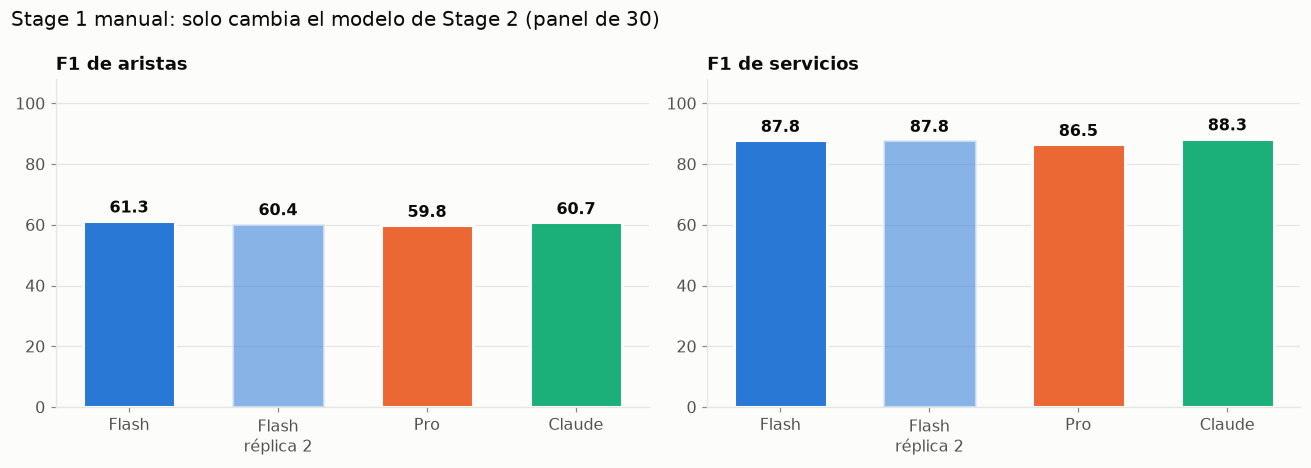

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
c.barras(ax[0], A, "edge", "F1 de aristas")
c.barras(ax[1], A, "svc", "F1 de servicios")
fig.suptitle("Stage 1 manual: solo cambia el modelo de Stage 2 (panel de 30)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
c.guardar(fig, "H1_medias")

## 2 · Las diferencias pareadas, video por video

Cada punto es la diferencia media entre dos corridas sobre los mismos 30 videos; la barra es
su intervalo de confianza del 95 %. La franja gris es el MDE del paper: lo que el diseño puede detectar.

comparación (B − A),Δ,IC 95 %,gana / pierde / empata,p (signos)
Gemini 3.6 Flash · réplica 2 − Gemini 3.6 Flash,-0.87,"[-2.77, +0.83]",3 / 5 / 22,0.727
Gemini 3.1 Pro − Gemini 3.6 Flash,-1.47,"[-5.63, +2.60]",9 / 12 / 9,0.664
Claude Opus 5.5 − Gemini 3.6 Flash,-0.52,"[-4.90, +3.75]",10 / 12 / 8,0.832
Claude Opus 5.5 − Gemini 3.1 Pro,+0.95,"[-1.66, +3.56]",11 / 8 / 11,0.648


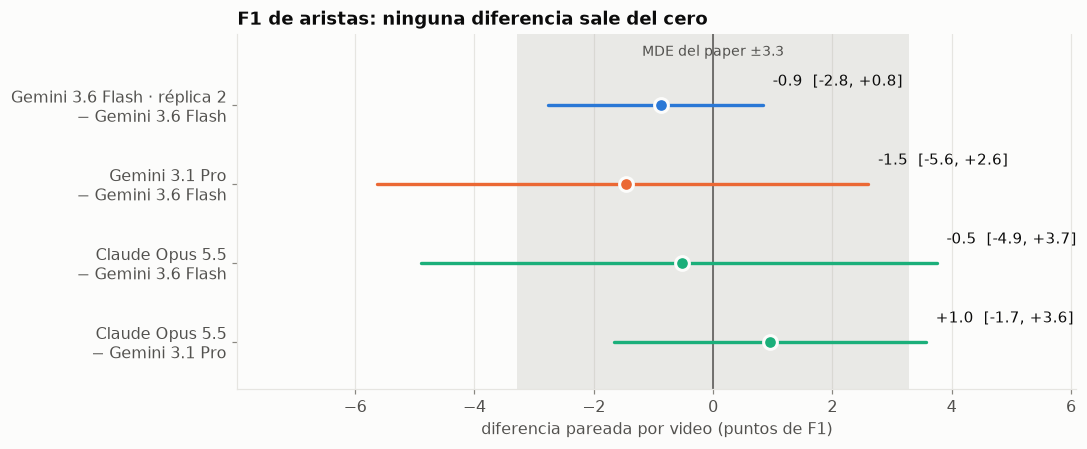

In [3]:
pares = [("A_flash", "A_flash_rep2"), ("A_flash", "A_pro"), ("A_flash", "A_claude"), ("A_pro", "A_claude")]
fig, ax = plt.subplots(figsize=(10, 4.2))
c.bosque(ax, pares, titulo="F1 de aristas: ninguna diferencia sale del cero", banda=3.29, banda_txt="MDE del paper")
fig.tight_layout()
c.guardar(fig, "H1_diferencias")
c.tabla_pareada(pares)

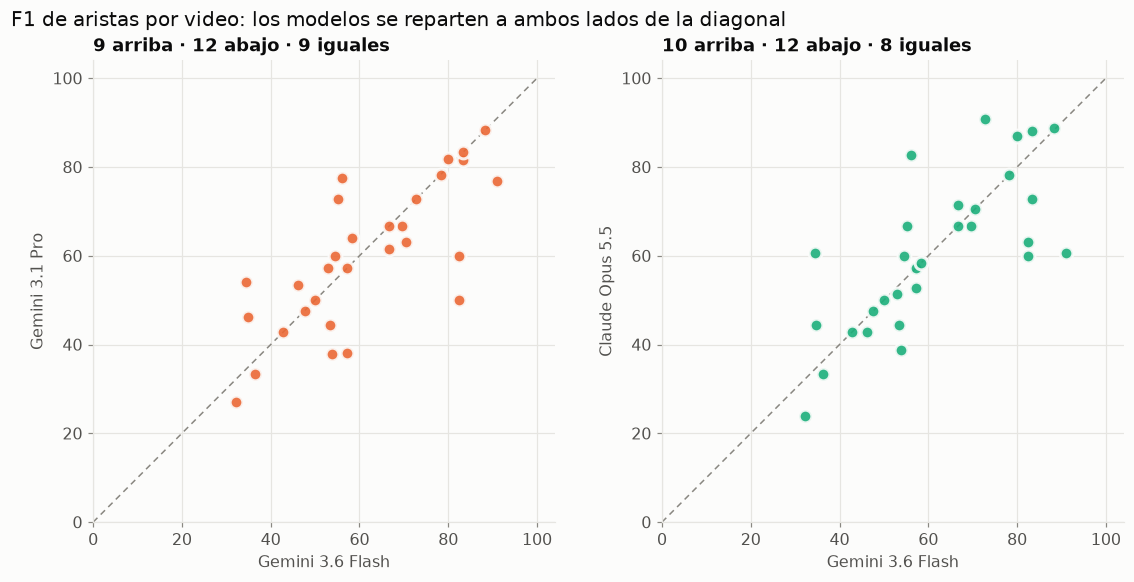

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 5.2))
c.dispersion(ax[0], "A_flash", "A_pro")
c.dispersion(ax[1], "A_flash", "A_claude")
fig.suptitle("F1 de aristas por video: los modelos se reparten a ambos lados de la diagonal", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
c.guardar(fig, "H1_por_video")

## 3 · El matiz: más aristas dibujadas, mismo F1

Pro y Claude dibujan unas dos aristas más por arquitectura que Flash. Ganan recall y pierden
precisión en la misma medida.

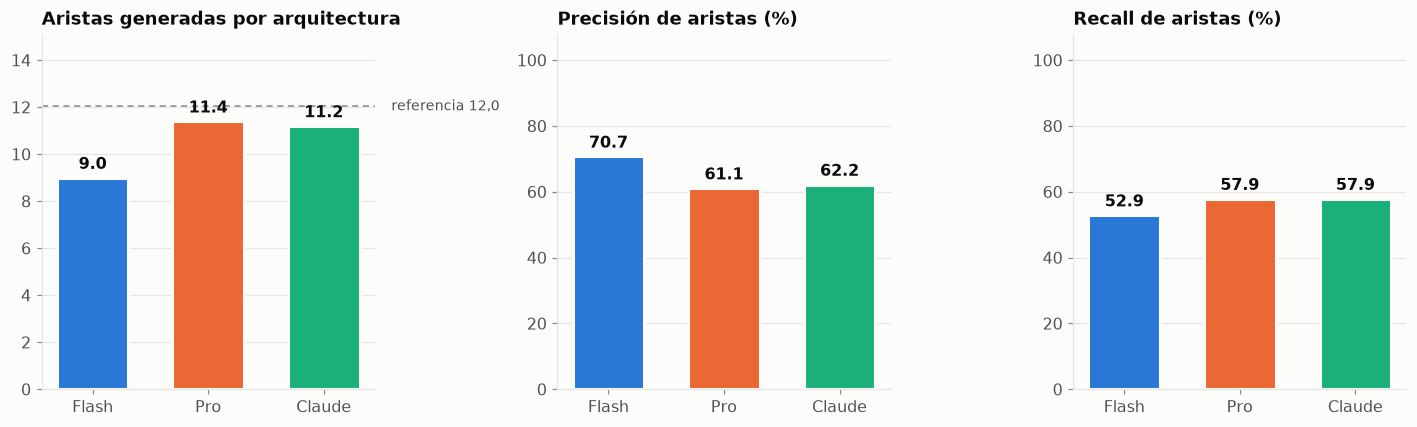

In [5]:
M = ["A_flash", "A_pro", "A_claude"]
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
c.barras(ax[0], M, "aristas", "Aristas generadas por arquitectura", ymax=14, ref={"referencia 12,0": 12.03})
c.barras(ax[1], M, "precision", "Precisión de aristas (%)")
c.barras(ax[2], M, "recall", "Recall de aristas (%)")
fig.tight_layout()
c.guardar(fig, "H1_conteo_precision_recall")

## 4 · Un video de ejemplo

Arriba la pizarra y la referencia; abajo lo que arma cada modelo con la misma transcripción manual.

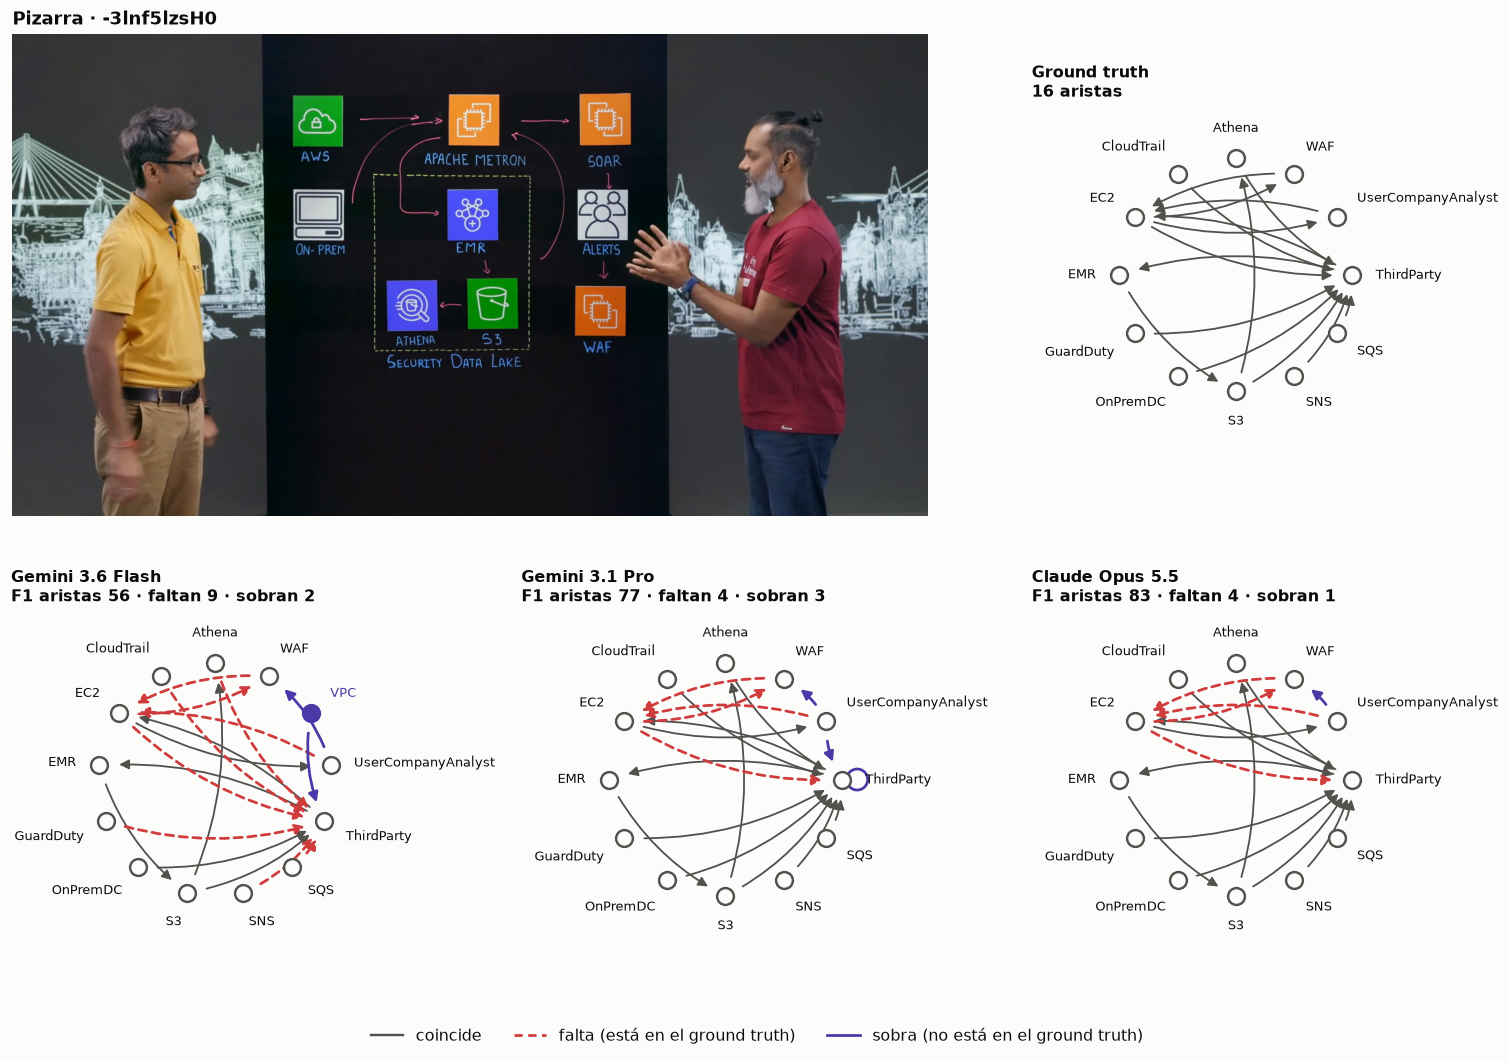

In [6]:
vid = "-3lnf5lzsH0"
fig = plt.figure(figsize=(14, 9.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1])
c.pizarra(fig.add_subplot(gs[0, :2]), vid)
c.grafo(fig.add_subplot(gs[0, 2]), vid)
for i, k in enumerate(M):
    c.grafo(fig.add_subplot(gs[1, i]), vid, c.filas(k)[vid], c.etiqueta(k))
c.leyenda_grafo(fig)
fig.tight_layout()
c.guardar(fig, "H1_ejemplo")

## Qué aporta al paper

Responde la objeción "esto es solo Flash": la brecha entre servicios y aristas se mantiene con
tres modelos de dos proveedores. Obliga a matizar la frase "dibuja menos conexiones de las que hay":
el conteo bajo es de Flash, no del problema.